In [1]:
import os
import urllib.request

if not os.path.exists("the-verdict.txt"):
    url = ("https://raw.githubusercontent.com/rasbt/"
           "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
           "the-verdict.txt")
    file_path = "the-verdict.txt"
    urllib.request.urlretrieve(url, file_path)

In [2]:
with open("the-verdict.txt","r", encoding="utf-8") as f:
    raw_data = f.read()

In [3]:
raw_data

'I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no great surprise to me to hear that, in the height of his glory, he had dropped his painting, married a rich widow, and established himself in a villa on the Riviera. (Though I rather thought it would have been Rome or Florence.)\n\n"The height of his glory"--that was what the women called it. I can hear Mrs. Gideon Thwing--his last Chicago sitter--deploring his unaccountable abdication. "Of course it\'s going to send the value of my picture \'way up; but I don\'t think of that, Mr. Rickham--the loss to Arrt is all I think of." The word, on Mrs. Thwing\'s lips, multiplied its _rs_ as though they were reflected in an endless vista of mirrors. And it was not only the Mrs. Thwings who mourned. Had not the exquisite Hermia Croft, at the last Grafton Gallery show, stopped me before Gisburn\'s "Moon-dancers" to say, with tears in her eyes: "We shall not look upon its like again"?\n\nWell!--even 

In [4]:
len(raw_data)

20479

In [5]:
import re

text = "Hello, word. this is a text."
result = re.split(r'(\s)', text)
print(result)

['Hello,', ' ', 'word.', ' ', 'this', ' ', 'is', ' ', 'a', ' ', 'text.']


In [6]:
result = re.split(r'([,.]|\s)', text)
print(result)

['Hello', ',', '', ' ', 'word', '.', '', ' ', 'this', ' ', 'is', ' ', 'a', ' ', 'text', '.', '']


In [7]:
result = [item for item in result if item.split()]
print(result)

['Hello', ',', 'word', '.', 'this', 'is', 'a', 'text', '.']


In [8]:
result = re.split(r'([,.:;?_!"()\']|--|\s)', raw_data)
result = [item.strip() for item in result if item.strip()]
preprocessed = result

In [9]:
len(preprocessed)

4690

In [10]:
preprocessed[:10]

['I',
 'HAD',
 'always',
 'thought',
 'Jack',
 'Gisburn',
 'rather',
 'a',
 'cheap',
 'genius']

In [11]:
all_words= sorted(set(preprocessed))
vocab_size = len(all_words)
print(vocab_size)

1130


In [12]:
vocab = {token:integer for integer,token in enumerate(all_words)}
len(vocab)

1130

In [13]:
len(vocab.items())

1130

In [14]:
class simpletokenizer:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i: s for s, i in vocab.items()}
    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [
        item.strip() for item in preprocessed if item.strip()
        ]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

In [15]:
tokenizer = simpletokenizer(vocab)

In [17]:
tokenizer.decode(idx)

NameError: name 'idx' is not defined

Adding Special context Token

In [18]:
all_tokens = sorted(set(list(preprocessed)))
all_tokens.extend(["<|endoftext|>","<|unk|>"])\

vocab = {token:integers for integers, token in enumerate(all_tokens)}

In [19]:
len(all_tokens)

1132

In [20]:
for i,item in enumerate(list(vocab.items())[-5:]):
    print(item)

('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


In [21]:
class simpletokenizer:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i: s for s, i in vocab.items()}
    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [
        item.strip() for item in preprocessed if item.strip()
        ]
        preprocessed = [
            item if item in self.str_to_int
            else "<|unk|>" for item in preprocessed
        ]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

In [22]:
Tokenizer = simpletokenizer(vocab)

In [23]:
text = '"My name is AB ". I am doing hhhh '
ids = Tokenizer.encode(text)
print(ids)

[1, 68, 1131, 584, 1131, 1, 7, 53, 150, 357, 1131]


In [24]:
import tiktoken

Byte Pair Encoding

In [25]:
tiktoken.__version__

'0.14.0'

In [26]:
tokenizer = tiktoken.get_encoding("gpt2")

In [27]:
encoded=tokenizer.encode("Hello, Abdullah is here")

In [28]:
tokenizer.decode(encoded)

'Hello, Abdullah is here'

In [29]:
text = ("hey, I am here now where are you? <|endoftext|>, unk come fast!!")

In [30]:
tokenizer.encode(text, allowed_special = {"<|endoftext|>"})

[20342,
 11,
 314,
 716,
 994,
 783,
 810,
 389,
 345,
 30,
 220,
 50256,
 11,
 555,
 74,
 1282,
 3049,
 3228]

Data Sampling with a sliding Window

In [31]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer.encode(raw_text)
print(len(enc_text))

5145


In [32]:
enc_sample = enc_text[50:]
print(len(enc_sample))

5095


In [33]:
context_size = 4
x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]
print(f"x: {x}")
print(f"y:      {y}")

x: [290, 4920, 2241, 287]
y:      [4920, 2241, 287, 257]


In [34]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]

    print(tokenizer.decode(context),"---->",tokenizer.decode([desired]))

 and ---->  established
 and established ---->  himself
 and established himself ---->  in
 and established himself in ---->  a


In [35]:
import torch

In [36]:
print(torch.__version__)

2.13.0+cpu


In [37]:
from torch.utils.data import Dataset,DataLoader

class GPTdatasetV1(Dataset):
    def __init__(self, txt, tokenizer, stride, max_length):
        self.input_ids=[]
        self.target_ids=[]

        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

        for i in range(0, len(token_ids)-max_length, stride):
            input_chunk=token_ids[i:i+max_length]
            target_chunk=token_ids[i+1:i+max_length+1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))
                                                           
    def __len__(self):\
       return len(self.input_ids)
    def __getitem__(self, idx):
       return self.input_ids[idx], self.target_ids[idx]                                                  

In [38]:
def create_DataLoader_V1(txt, batch_size=4, stride=128,
                        max_length=256, shuffle=False,
                        drop_last=True, num_workers=0):

    tokenizer = tiktoken.get_encoding("gpt2")

    dataset = GPTdatasetV1(txt, tokenizer,stride, max_length)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader                             

In [39]:
dataloader = create_DataLoader_V1(
    raw_text,batch_size=1,max_length=4,stride=1,shuffle=False
)
data_iter = iter(dataloader)
first_batch = next(data_iter)
print(first_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


In [40]:
data_iter = iter(dataloader)

for i in range(1,5):
    first_batch = next(data_iter)
    print(first_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]
[tensor([[ 367, 2885, 1464, 1807]]), tensor([[2885, 1464, 1807, 3619]])]
[tensor([[2885, 1464, 1807, 3619]]), tensor([[1464, 1807, 3619,  402]])]
[tensor([[1464, 1807, 3619,  402]]), tensor([[1807, 3619,  402,  271]])]



Token Embedding 

In [41]:
input_ids = ([3,5,2,1])

In [42]:
vocab_size =6
output_dim=5

torch.manual_seed(123)
embedding_layer=torch.nn.Embedding(vocab_size, output_dim)

In [43]:
print(embedding_layer.weight)

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.3035, -0.5880,  0.3486],
        [ 0.6603, -0.2196, -0.3792,  0.7671, -1.1925],
        [ 0.6984, -1.4097,  0.1794,  1.8951,  1.3689],
        [-1.6033, -1.3250,  0.1784, -2.1338,  1.0524],
        [-0.3885, -0.9343,  1.8319, -0.3378,  0.8805],
        [ 1.5542,  0.6266, -0.1755,  0.0983, -0.0935]], requires_grad=True)


In [44]:
embedding_layer(torch.tensor([1]))

tensor([[ 0.6603, -0.2196, -0.3792,  0.7671, -1.1925]],
       grad_fn=<EmbeddingBackward0>)

In [45]:
embedding_layer(torch.tensor(input_ids))

tensor([[-1.6033, -1.3250,  0.1784, -2.1338,  1.0524],
        [ 1.5542,  0.6266, -0.1755,  0.0983, -0.0935],
        [ 0.6984, -1.4097,  0.1794,  1.8951,  1.3689],
        [ 0.6603, -0.2196, -0.3792,  0.7671, -1.1925]],
       grad_fn=<EmbeddingBackward0>)

In [46]:
vocab_size =tokenizer.n_vocab
output_dim=5

torch.manual_seed(123)
embedding_layer=torch.nn.Embedding(tokenizer.n_vocab, output_dim)

In [47]:
embedding_layer(torch.tensor([2000]))

tensor([[-0.0347,  1.4909,  1.3087,  0.8410, -0.8296]],
       grad_fn=<EmbeddingBackward0>)

In [48]:
vocab_size =50257
output_dim=256

#torch.manual_seed(123)
embedding_layer=torch.nn.Embedding(tokenizer.n_vocab, output_dim)

Encoding Word Position

In [49]:
vocab_size =50257
output_dim=256

#torch.manual_seed(123)
embedding_layer=torch.nn.Embedding(vocab_size, output_dim)

In [50]:
max_length=4
dataloader = create_DataLoader_V1(
    raw_text,batch_size=8,max_length=max_length,stride=max_length,shuffle=False
)
data_iter = iter(dataloader)
inputs,target=next(data_iter)

In [51]:
print("Token ID:\n", inputs)
print("Input shape:\n", inputs.shape)

Token ID:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])
Input shape:
 torch.Size([8, 4])


In [52]:
token_embedding=embedding_layer(inputs)
token_embedding.shape

torch.Size([8, 4, 256])

In [53]:
context_length=max_length
pos_embedding_layer = torch.nn.Embedding(context_length,output_dim)

In [54]:
torch.arange(max_length)

tensor([0, 1, 2, 3])

In [55]:
pos_embedding_layer.weight

Parameter containing:
tensor([[-0.4132, -1.4744,  0.4229,  ..., -0.7495, -0.7122,  0.9711],
        [-1.3814, -1.7236, -0.6629,  ..., -1.3779, -0.2915,  0.6481],
        [ 0.4157, -1.2844,  0.6054,  ...,  1.0503, -0.9726,  0.2204],
        [ 1.3464,  1.3051,  0.4203,  ...,  0.5321, -0.1665, -0.8272]],
       requires_grad=True)

In [56]:
pos_embedding_layer(torch.arange(max_length))

tensor([[-0.4132, -1.4744,  0.4229,  ..., -0.7495, -0.7122,  0.9711],
        [-1.3814, -1.7236, -0.6629,  ..., -1.3779, -0.2915,  0.6481],
        [ 0.4157, -1.2844,  0.6054,  ...,  1.0503, -0.9726,  0.2204],
        [ 1.3464,  1.3051,  0.4203,  ...,  0.5321, -0.1665, -0.8272]],
       grad_fn=<EmbeddingBackward0>)

In [57]:
pos_embedding=pos_embedding_layer(torch.arange(max_length))
print(pos_embedding.shape)

torch.Size([4, 256])


In [58]:
input_embeddings = token_embedding + pos_embedding
print(input_embeddings.shape)

torch.Size([8, 4, 256])


In [59]:
token_embedding[1] + pos_embedding

tensor([[-2.6642, -2.0958,  1.1607,  ..., -0.5142, -1.0579,  0.3700],
        [-0.4719, -0.0202, -1.5442,  ..., -2.8201,  0.8258, -0.3809],
        [-1.3811, -1.4651, -0.6144,  ..., -0.8546, -4.3282, -0.0964],
        [ 1.4573,  1.1675,  1.3489,  ...,  0.3292, -2.7239, -0.3721]],
       grad_fn=<AddBackward0>)

In [60]:
token_embedding + pos_embedding

tensor([[[-0.6150, -1.1624,  0.5930,  ..., -0.2741,  0.3907,  1.1845],
         [-1.6539, -1.0175, -1.4117,  ..., -1.6973,  0.2840, -0.6858],
         [ 0.0831, -1.6180, -1.7072,  ...,  0.5081, -2.8745,  1.2650],
         [ 2.1252, -0.5971,  0.8300,  ...,  0.9725, -0.4918, -1.1878]],

        [[-2.6642, -2.0958,  1.1607,  ..., -0.5142, -1.0579,  0.3700],
         [-0.4719, -0.0202, -1.5442,  ..., -2.8201,  0.8258, -0.3809],
         [-1.3811, -1.4651, -0.6144,  ..., -0.8546, -4.3282, -0.0964],
         [ 1.4573,  1.1675,  1.3489,  ...,  0.3292, -2.7239, -0.3721]],

        [[-0.4987, -2.1702,  0.9013,  ..., -1.8066,  1.6375,  0.8739],
         [-2.0982, -2.1780,  1.3890,  ..., -1.0434,  0.5432,  1.2273],
         [ 0.6280, -1.5131, -0.8556,  ...,  1.3125, -0.3333,  1.3427],
         [-0.9262,  1.0444, -1.0789,  ...,  1.7559,  0.4222, -1.7032]],

        ...,

        [[-0.3246, -1.3449,  0.0487,  ..., -2.3380, -1.7831,  3.1606],
         [-0.3356, -1.7454,  0.4674,  ..., -2.5511,  0.36

Simple Self Attention Mechanism Without Training


In [61]:
import torch

inputs = torch.tensor([
    [0.21,0.53,0.21], #your     x^1
    [0.99,0.15,0.33], #journey  x^2
    [0.78,0.43,0.77], #startn   x^3
    [0.71,0.25,0.19], #with     x^4
    [0.15,0.89,0.61], #one      x^5
    [0.55,0.09,0.91]  #step     x^6
])

In [62]:
input_query = inputs[1]
input_query

tensor([0.9900, 0.1500, 0.3300])

In [63]:
input1 = inputs[0]
input1

tensor([0.2100, 0.5300, 0.2100])

In [64]:
0.99*0.21 + 0.15*0.53 + 0.33*0.21

0.3567

In [65]:
torch.dot(input_query,input1)

tensor(0.3567)

In [66]:
for idx, ele in enumerate(inputs[0]):
    print(inputs[0][idx])

tensor(0.2100)
tensor(0.5300)
tensor(0.2100)


In [67]:
res = 0
i=0
for idx,element in enumerate(inputs[i]):
    res += inputs[i][idx] * input_query[idx]
print(res)

tensor(0.3567)


In [68]:
query = inputs[1]
att_score_2 = torch.empty(inputs.shape[0])
for i,x_i in enumerate(inputs):
    att_score_2[i]=torch.dot(x_i, query)
print(att_score_2)

tensor([0.3567, 1.1115, 1.0908, 0.8031, 0.4833, 0.8583])


In [69]:
inputs.shape[0]

6

In [70]:
att_weight_2 = att_score_2/att_score_2.sum()
att_weight_2

tensor([0.0758, 0.2363, 0.2319, 0.1707, 0.1027, 0.1825])

In [71]:
att_weight_2.sum()

tensor(1.)

In [72]:
def softmax_naive(x):
    return torch.exp(x)/torch.exp(x).sum(dim=0)
softmax_naive(att_score_2)

tensor([0.1046, 0.2225, 0.2180, 0.1635, 0.1187, 0.1727])

In [73]:
torch.softmax(att_score_2, dim=0)

tensor([0.1046, 0.2225, 0.2180, 0.1635, 0.1187, 0.1727])

In [74]:
torch.zeros(query.shape)

tensor([0., 0., 0.])

In [75]:
query = inputs[1]

context_vector = torch.zeros(query.shape)

for i, x_i in enumerate(inputs):
    context_vector += att_weight_2[1][i] * x_i

print(context_vector)

IndexError: invalid index of a 0-dim tensor. Use `tensor.item()` in Python or `tensor.item<T>()` in C++ to convert a 0-dim tensor to a number

In [ ]:
context_vector

In [ ]:
att_scores = torch.empty(6,6)

for i,x_i in enumerate(inputs):
    for j,x_j in enumerate(inputs):
        att_scores[i,j] = torch.dot(x_i,x_j)
print(att_scores)

In [76]:
att_scores = inputs @ inputs.T
att_scores

tensor([[0.3691, 0.3567, 0.5534, 0.3215, 0.6313, 0.3543],
        [0.3567, 1.1115, 1.0908, 0.8031, 0.4833, 0.8583],
        [0.5534, 1.0908, 1.3862, 0.8076, 0.9694, 1.1684],
        [0.3215, 0.8031, 0.8076, 0.6027, 0.4449, 0.5859],
        [0.6313, 0.4833, 0.9694, 0.4449, 1.1867, 0.7177],
        [0.3543, 0.8583, 1.1684, 0.5859, 0.7177, 1.1387]])

In [77]:
att_weight = torch.softmax(att_scores,dim=0)
att_weight

tensor([[0.1556, 0.1046, 0.1035, 0.1249, 0.1444, 0.1020],
        [0.1536, 0.2225, 0.1771, 0.2022, 0.1245, 0.1689],
        [0.1870, 0.2180, 0.2379, 0.2032, 0.2024, 0.2303],
        [0.1483, 0.1635, 0.1334, 0.1655, 0.1198, 0.1286],
        [0.2022, 0.1187, 0.1568, 0.1414, 0.2516, 0.1467],
        [0.1533, 0.1727, 0.1914, 0.1628, 0.1574, 0.2235]])

In [78]:
torch.sum(torch.tensor([0.1556, 0.1046, 0.1035, 0.1249, 0.1444, 0.1020]))

tensor(0.7350)

In [79]:
att_weight.sum(dim=0)

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])

In [80]:
all_context_vec = att_weight @ inputs
all_context_vec

tensor([[0.3834, 0.3115, 0.3515],
        [0.6458, 0.3675, 0.5101],
        [0.7419, 0.4858, 0.6660],
        [0.5032, 0.3201, 0.4094],
        [0.5011, 0.4648, 0.5162],
        [0.6146, 0.3903, 0.5669]])

Implenting Self Attention with trainable Weights

Computing the attention weights step by step

In [81]:
inputs

tensor([[0.2100, 0.5300, 0.2100],
        [0.9900, 0.1500, 0.3300],
        [0.7800, 0.4300, 0.7700],
        [0.7100, 0.2500, 0.1900],
        [0.1500, 0.8900, 0.6100],
        [0.5500, 0.0900, 0.9100]])

In [82]:
x_2 = inputs[1]
d_in = inputs.shape[1]
d_out = 2

In [83]:
torch.manual_seed(124)
w_query = torch.nn.Parameter(torch.rand(d_in,d_out))
w_key = torch.nn.Parameter(torch.rand(d_in,d_out))
w_value = torch.nn.Parameter(torch.rand(d_in,d_out))
w_query

Parameter containing:
tensor([[0.1526, 0.6311],
        [0.8407, 0.4741],
        [0.5123, 0.1231]], requires_grad=True)

In [84]:
w_key

Parameter containing:
tensor([[0.3097, 0.4665],
        [0.4847, 0.2217],
        [0.1413, 0.4469]], requires_grad=True)

In [85]:
w_value

Parameter containing:
tensor([[0.9984, 0.9203],
        [0.2416, 0.5610],
        [0.0827, 0.5029]], requires_grad=True)

In [86]:
query_2 = x_2 @ w_query
query_2

tensor([0.4462, 0.7366], grad_fn=<SqueezeBackward4>)

In [87]:
inputs,w_query

(tensor([[0.2100, 0.5300, 0.2100],
         [0.9900, 0.1500, 0.3300],
         [0.7800, 0.4300, 0.7700],
         [0.7100, 0.2500, 0.1900],
         [0.1500, 0.8900, 0.6100],
         [0.5500, 0.0900, 0.9100]]),
 Parameter containing:
 tensor([[0.1526, 0.6311],
         [0.8407, 0.4741],
         [0.5123, 0.1231]], requires_grad=True))

In [88]:
keys = inputs@w_key
values = inputs@w_value

keys.shape

torch.Size([6, 2])

In [89]:
keys_2 = keys[1]
att_score_22 = torch.dot(query_2,keys_2)
att_score_22

tensor(0.6634, grad_fn=<DotBackward0>)

In [90]:
att_score_2 = query_2 @ keys.T
att_score_2

tensor([0.3847, 0.6634, 0.8411, 0.5115, 0.6494, 0.6561],
       grad_fn=<SqueezeBackward4>)

In [91]:
d_f = keys.shape[1]
att_weight_2 = torch.softmax(att_score_2/d_f**0.5, dim=-1)
att_weight_2

tensor([0.1407, 0.1713, 0.1942, 0.1538, 0.1696, 0.1704],
       grad_fn=<SoftmaxBackward0>)

In [92]:
att_weight_2.sum()

tensor(1., grad_fn=<SumBackward0>)

In [93]:
context_vector_2 = att_weight_2@ values
context_vector_2

tensor([0.7152, 1.0140], grad_fn=<SqueezeBackward4>)

Implementing a compact SelfAttention Class

In [94]:
import torch.nn as nn

class SelfAttention_V1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.w_query = torch.nn.Parameter(torch.rand(d_in,d_out))
        self.w_key = torch.nn.Parameter(torch.rand(d_in,d_out))
        self.w_value = torch.nn.Parameter(torch.rand(d_in,d_out))
    def forward(self, x):
        queries = inputs @ w_query
        keys = inputs @ w_key
        values = inputs @ w_value
        att_scores = queries@keys.T
        att_weights = torch.softmax(att_scores/d_f**0.5, dim=-1)
        context_vec = att_weights@values
        return context_vec
torch.manual_seed(123)
sa_v1 = SelfAttention_V1(d_in,d_out)
sa_v1(inputs)

tensor([[0.7092, 1.0072],
        [0.7152, 1.0140],
        [0.7171, 1.0191],
        [0.7123, 1.0102],
        [0.7137, 1.0161],
        [0.7110, 1.0099]], grad_fn=<MmBackward0>)

In [95]:
inputs

tensor([[0.2100, 0.5300, 0.2100],
        [0.9900, 0.1500, 0.3300],
        [0.7800, 0.4300, 0.7700],
        [0.7100, 0.2500, 0.1900],
        [0.1500, 0.8900, 0.6100],
        [0.5500, 0.0900, 0.9100]])

In [96]:
class SelfAttention_V1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()

        self.w_query = nn.Parameter(torch.rand(d_in, d_out))
        self.w_key = nn.Parameter(torch.rand(d_in, d_out))
        self.w_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):

        queries = x @ self.w_query
        keys = x @ self.w_key
        values = x @ self.w_value

        att_scores = queries @ keys.T

        att_weights = torch.softmax(
            att_scores / (d_out ** 0.5),
            dim=-1
        )

        context_vec = att_weights @ values

        return context_vec

torch.manual_seed(789)
sa_v1 = SelfAttention_V1(d_in,d_out)
sa_v1(inputs)

tensor([[0.7627, 0.7654],
        [0.7653, 0.7831],
        [0.7692, 0.7879],
        [0.7635, 0.7747],
        [0.7699, 0.7758],
        [0.7600, 0.7755]], grad_fn=<MmBackward0>)

In [97]:
import torch
import torch.nn as nn

class SelfAttention_V1(nn.Module):
    def __init__(self, d_in, d_out, qkv_biase=False):
        super().__init__()
        self.w_query = torch.nn.Linear(d_in,d_out,bias=qkv_biase)
        self.w_key = torch.nn.Linear(d_in,d_out,bias=qkv_biase)
        self.w_value = torch.nn.Linear(d_in,d_out,bias=qkv_biase)
    def forward(self, x):
        queries = self.w_query(inputs)
        keys = self.w_key(inputs)
        values = self.w_value(inputs)
        att_scores = queries@keys.T
        att_weights = torch.softmax(att_scores/d_f**0.5, dim=-1)
        context_vec = att_weights@values
        return context_vec
torch.manual_seed(123)
sa_v1 = SelfAttention_V1(d_in,d_out)
sa_v1(inputs)

tensor([[-0.5202, -0.0466],
        [-0.5251, -0.0411],
        [-0.5258, -0.0407],
        [-0.5229, -0.0434],
        [-0.5209, -0.0465],
        [-0.5270, -0.0388]], grad_fn=<MmBackward0>)

Hiding Future Words With Casual Attention

Applying a Casual Attention Mask

In [98]:
queries = sa_v1.w_query(inputs)
keys=sa_v1.w_key(inputs)
values=sa_v1.w_value(inputs)

In [99]:
att_scores = queries@ keys.T
att_weight = torch.softmax(att_scores/d_f**0.5, dim=-1)

In [100]:
context_length = att_scores.shape[0]

In [101]:
context_length

6

In [102]:
mask_simple = torch.tril(torch.ones(context_length,context_length))

In [103]:
mask_simple

tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])

In [104]:
mask_simple = att_weight*mask_simple
mask_simple

tensor([[0.1672, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1535, 0.1709, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1519, 0.1709, 0.1801, 0.0000, 0.0000, 0.0000],
        [0.1594, 0.1684, 0.1734, 0.1636, 0.0000, 0.0000],
        [0.1655, 0.1646, 0.1695, 0.1640, 0.1722, 0.0000],
        [0.1485, 0.1734, 0.1821, 0.1610, 0.1603, 0.1747]],
       grad_fn=<MulBackward0>)

In [105]:
raw_simple = mask_simple.sum(dim=-1, keepdim=True)
mask_simple_norm = mask_simple/raw_simple
print(mask_simple_norm)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4733, 0.5267, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3021, 0.3398, 0.3581, 0.0000, 0.0000, 0.0000],
        [0.2398, 0.2533, 0.2608, 0.2461, 0.0000, 0.0000],
        [0.1980, 0.1969, 0.2028, 0.1962, 0.2060, 0.0000],
        [0.1485, 0.1734, 0.1821, 0.1610, 0.1603, 0.1747]],
       grad_fn=<DivBackward0>)


In [106]:
raw_simple

tensor([[0.1672],
        [0.3244],
        [0.5029],
        [0.6648],
        [0.8358],
        [1.0000]], grad_fn=<SumBackward1>)

In [107]:
mask= torch.triu(torch.ones(context_length,context_length), diagonal=1)
masked = att_scores.masked_fill(mask.bool(), -torch.inf)
print(masked)

tensor([[0.0422,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.1289, 0.2803,   -inf,   -inf,   -inf,   -inf],
        [0.1580, 0.3243, 0.3984,   -inf,   -inf,   -inf],
        [0.0870, 0.1645, 0.2059, 0.1239,   -inf,   -inf],
        [0.0807, 0.0730, 0.1147, 0.0676, 0.1369,   -inf],
        [0.1527, 0.3724, 0.4415, 0.2672, 0.2611, 0.3828]],
       grad_fn=<MaskedFillBackward0>)


In [108]:
att_weight = torch.softmax(masked/d_f**0.5, dim=-1)
att_weight

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4733, 0.5267, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3021, 0.3398, 0.3581, 0.0000, 0.0000, 0.0000],
        [0.2398, 0.2533, 0.2608, 0.2461, 0.0000, 0.0000],
        [0.1980, 0.1969, 0.2028, 0.1962, 0.2060, 0.0000],
        [0.1485, 0.1734, 0.1821, 0.1610, 0.1603, 0.1747]],
       grad_fn=<SoftmaxBackward0>)

#Masking Additional Attention Weights with Dropout

In [109]:
torch.manual_seed(123)
layer = torch.nn.Dropout(0.5)

In [110]:
example = torch.ones(6,6)
example

tensor([[1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.]])

In [111]:
layer(example)

tensor([[2., 2., 0., 2., 2., 0.],
        [0., 0., 0., 2., 0., 2.],
        [2., 2., 2., 2., 0., 2.],
        [0., 2., 2., 0., 0., 2.],
        [0., 2., 0., 2., 0., 2.],
        [0., 2., 2., 2., 2., 0.]])

In [112]:
dropout_layer = 0.5
1/(1-dropout_layer)

2.0

In [113]:
layer(att_weight)

tensor([[2.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.6796, 0.7162, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.5216, 0.4922, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.4121, 0.0000],
        [0.2969, 0.3468, 0.0000, 0.3220, 0.3206, 0.3494]],
       grad_fn=<MulBackward0>)

#Implementing a compact Casual Self-Attention Mechanism

In [114]:
batch = torch.stack((inputs,inputs), dim=0)
batch.shape

torch.Size([2, 6, 3])

In [115]:
import torch
import torch.nn as nn

class CasualAttention(nn.Module):
    def __init__(self, d_in, d_out,context_length, dropout,qkv_biase=False):
        super().__init__()
        self.w_query = torch.nn.Linear(d_in,d_out,bias=qkv_biase)
        self.w_key = torch.nn.Linear(d_in,d_out,bias=qkv_biase)
        self.w_value = torch.nn.Linear(d_in,d_out,bias=qkv_biase)
        self.dropout = torch.nn.Dropout(dropout)
        self.register_buffer("mask",torch.triu(torch.ones(context_length,context_length), diagonal=1))
    def forward(self, x):
        b,num_tokens,d_in=x.shape
        queries = self.w_query(x)
        keys = self.w_key(x)
        values = self.w_value(x)
        
        att_scores = queries@keys.transpose(1,2)
        att_scores=att_scores.masked_fill(
          self.mask.bool()[:num_tokens, :num_tokens], -torch.inf
        )
        att_weights = torch.softmax(att_scores/keys.shape[-1]**0.5, dim=-1)
        att_weights = self.dropout(att_weights)
        context_vec = att_weights@values
        return context_vec
torch.manual_seed(123)

context_length = batch.shape[1]
dropout=0.0
ca = CasualAttention(d_in,d_out, context_length, dropout)
ca(batch)

tensor([[[-0.3331, -0.1779],
         [-0.4777, -0.1124],
         [-0.5563, -0.0672],
         [-0.5324, -0.0820],
         [-0.5262, -0.1032],
         [-0.5270, -0.0388]],

        [[-0.3331, -0.1779],
         [-0.4777, -0.1124],
         [-0.5563, -0.0672],
         [-0.5324, -0.0820],
         [-0.5262, -0.1032],
         [-0.5270, -0.0388]]], grad_fn=<UnsafeViewBackward0>)

Extending Single Head Attention To Multi Head Attention 

Stacking Multi Single Head Attention Layer

In [116]:
class MultiHeadAttention(nn.Module):
    def __init__(self,d_in,d_out, context_length, dropout,num_head=2, qkv_biase=False):
        super(). __init__()
        self.head =nn.ModuleList([
            CasualAttention(d_in, d_out, context_length, dropout, qkv_biase) for _ in range(num_head)
        ])
    def forward(self,x):
        return torch.cat([head(x) for head in self.head], dim=-1)
torch.manual_seed(123)
d_in, d_out = 3,2
mha = MultiHeadAttention(d_in,d_out, context_length, dropout=0.0, qkv_biase=False)
mha(batch)

tensor([[[-0.3331, -0.1779,  0.3025,  0.2883],
         [-0.4777, -0.1124,  0.4583,  0.2852],
         [-0.5563, -0.0672,  0.5307,  0.3002],
         [-0.5324, -0.0820,  0.5185,  0.2941],
         [-0.5262, -0.1032,  0.5049,  0.3184],
         [-0.5270, -0.0388,  0.5083,  0.2886]],

        [[-0.3331, -0.1779,  0.3025,  0.2883],
         [-0.4777, -0.1124,  0.4583,  0.2852],
         [-0.5563, -0.0672,  0.5307,  0.3002],
         [-0.5324, -0.0820,  0.5185,  0.2941],
         [-0.5262, -0.1032,  0.5049,  0.3184],
         [-0.5270, -0.0388,  0.5083,  0.2886]]], grad_fn=<CatBackward0>)

#Implementing Multi Head Attention With Weight Split

In [117]:
class MultiHeadAttention(nn.Module):
    def __init__(self,d_in,d_out, context_length, dropout=0.0, num_head=2, qkv_biase=False):
        super(). __init__()
        assert d_out % num_head == 0
        #d_out must be divisible by num_heads

        self.d_out = d_out
        self.num_head = num_head
        self.head_dim = d_out // num_head #reduce the projection dim to match desired output dim

        self.w_query = nn.Linear(d_in, d_out, bias=qkv_biase)
        self.w_key = nn.Linear(d_in, d_out, bias=qkv_biase)
        self.w_value= nn.Linear(d_in, d_out, bias=qkv_biase)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask", torch.triu(torch.ones(context_length,context_length), diagonal=1)
        )
    def forward(self,x):
        b,num_tokens, d_in = x.shape
        keys= self.w_key(x)
        queries = self.w_query(x)
        values = self.w_value(x)
    #we implicity split the matrix by adding "num_heads" dimension
    #unroll last dim:(b, num_tokens, d_out) --> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_head, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_head, self.head_dim)
        values = values.view(b, num_tokens, self.num_head, self.head_dim)
    #Transpose
        keys = keys.transpose(1,2)
        queries = queries.transpose(1,2)
        values = values.transpose(1,2)
        #compute scale dot product attention(aka self_attention) with a casual mask
        att_scores = queries @ keys.transpose(2,3)
        #original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]
        #use the mask to fill attention score
        att_scores=att_scores.masked_fill(mask_bool, -torch.inf)
        att_weight = torch.softmax(att_scores/keys.shape[-1]**0.5, dim=-1 )
        att_weight = self.dropout(att_weight)
         #shape(b, num_tokens, num_heads, head_dim)
        context_vector = (att_weight @ values).transpose(1,2)
        #combine heads where self.d_out = self.num_head * self.head_dim
        context_vector = context_vector.reshape(b, num_tokens, self.d_out)
        context_vector = self.out_proj(context_vector)

        return context_vector
torch.manual_seed(123)
batch_size, context_length, d_in = batch.shape
d_out = 4
mha = MultiHeadAttention(d_in,d_out,context_length=context_length, num_head=2)
context_vector = mha(batch)
print(context_vector)

tensor([[[-0.0056,  0.2583, -0.0616, -0.3179],
         [-0.0015,  0.2527, -0.0674, -0.3471],
         [ 0.0029,  0.2760, -0.0709, -0.3725],
         [ 0.0008,  0.2659, -0.0700, -0.3636],
         [-0.0082,  0.2775, -0.0692, -0.3517],
         [ 0.0165,  0.2863, -0.0720, -0.3957]],

        [[-0.0056,  0.2583, -0.0616, -0.3179],
         [-0.0015,  0.2527, -0.0674, -0.3471],
         [ 0.0029,  0.2760, -0.0709, -0.3725],
         [ 0.0008,  0.2659, -0.0700, -0.3636],
         [-0.0082,  0.2775, -0.0692, -0.3517],
         [ 0.0165,  0.2863, -0.0720, -0.3957]]], grad_fn=<ViewBackward0>)


#implementing a GPT model from scratch to generate text

In [118]:
GPT_Config_124M = {
  "vocab_size":50257,
  "context_length":1024,
  "emb_dim":768,
  "n_heads":12,
  "n_layers":12,
  "drop_rate":0.1,
  "qkv_biase":False
}

In [119]:
import torch
import torch.nn as nn
class DummyGPTModel(nn.Module):
    def __init__(self, clg):
        super().__init__()
        self.tok_emb = nn.Embedding(clg["vocab_size"],clg["emb_dim"])
        self.pos_emb = nn.Embedding(clg["context_length"],clg["emb_dim"])
        self.drop_emb = nn.Dropout(clg["drop_rate"])
        #Use a placeholder for transformer block
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(clg) for _ in range(clg["n_layers"])]
        )
        #Use a placeholder for norm
        self.final_norm = DummyLayerNorm(clg["emb_dim"])
        self.out_head=nn.Linear(
            clg["emb_dim"], clg["vocab_size"], bias = False
        )
    def forward(self, in_idx):
        batch_size, seq_length = in_idx.shape
        tok_embs = self.tok_emb(in_idx)
        pos_embs = self.pos_emb(torch.arange(seq_length, device=in_idx.device))
        x = tok_embs + pos_embs
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits
class DummyTransformerBlock(nn.Module):
    def __init__(self,clg):
        super().__init__()

    def forward(self,x):
        return x

class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()
    def forward(self,x):
        return x

In [120]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
txt1 = "My name is Abdullah"
txt2 = "I am doing CS"
batch = []
batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[ 3666,  1438,   318, 26804],
        [   40,   716,  1804,  9429]])


In [121]:
torch.manual_seed(123)
model = DummyGPTModel(clg=GPT_Config_124M)
logits = model(batch)
print("Logits_shape", logits.shape)
print(logits)

Logits_shape torch.Size([2, 4, 50257])
tensor([[[-1.9571e-01, -5.8482e-01, -1.4869e+00,  ...,  1.5647e+00,
          -2.7483e-01, -1.8199e-03],
         [-3.0570e-01,  1.0359e+00, -6.8376e-01,  ...,  1.0807e-01,
          -3.9296e-01,  7.1136e-01],
         [ 2.6759e-01,  8.9002e-02, -4.1191e-01,  ...,  1.5699e-01,
           8.8172e-01, -4.7825e-01],
         [ 2.2112e-02,  7.3308e-02, -4.5309e-02,  ...,  1.6859e+00,
          -1.8079e-01,  4.4153e-01]],

        [[ 3.2283e-01, -9.8592e-01, -1.4169e-01,  ..., -2.4592e-01,
           8.9048e-01, -7.2864e-02],
         [-8.7038e-01,  1.3751e+00, -4.4786e-01,  ..., -5.1482e-01,
          -5.4749e-01,  8.6226e-01],
         [-1.1149e+00,  7.1820e-01, -1.9957e-01,  ..., -1.1523e-01,
          -8.9276e-01, -2.3503e-01],
         [-1.2427e-02,  2.4527e-01, -1.5697e+00,  ...,  2.2886e+00,
          -9.2327e-01,  1.6826e-02]]], grad_fn=<UnsafeViewBackward0>)


In [122]:
batch.shape

torch.Size([2, 4])

Normalizing activities with layer normalizing

In [123]:
torch.manual_seed(123)

batch = torch.randn(2,5)
print(batch)

tensor([[-0.1115,  0.1204, -0.3696, -0.2404, -1.1969],
        [ 0.2093, -0.9724, -0.7550,  0.3239, -0.1085]])


In [124]:
layer = nn.Sequential(nn.Linear(5,6), nn.ReLU())
out = layer(batch)
print(out)

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


In [125]:
mean = out.mean(dim=-1, keepdim = True)
print(mean)

tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)


In [126]:
var = out.var(dim=-1, keepdim = True)
print(var)

tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


In [127]:
normed = ((out-mean)/torch.sqrt(var))
normed.var(dim=-1, keepdim=True)

tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)

In [128]:
torch.set_printoptions(sci_mode=False)

In [129]:
class layernorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))
    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True)#unbiased=False
        x_norm = (x-mean)/torch.sqrt(var - self.eps)
        return  self.scale*x_norm + self.shift

In [130]:
ln = layernorm(6)
output_normed=ln(out)

In [131]:
out

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)

In [132]:
batch

tensor([[-0.1115,  0.1204, -0.3696, -0.2404, -1.1969],
        [ 0.2093, -0.9724, -0.7550,  0.3239, -0.1085]])

In [133]:
output_normed.mean(dim=-1, keepdim=True)

tensor([[-0.0000],
        [ 0.0000]], grad_fn=<MeanBackward1>)

In [134]:
output_normed.var(dim=-1, keepdim=True)

tensor([[1.0004],
        [1.0003]], grad_fn=<VarBackward0>)

#Implementing a Feed Forward Network With GeLU activation

In [135]:
class GeLU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5*x*(1+torch.tanh(torch.sqrt(torch.tensor(2.0/torch.pi))*
               (x + 0.044715 * torch.pow(x,3))
                ))
        

In [136]:
class Feedforward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4*cfg["emb_dim"]),
            GeLU(),
            nn.Linear(4*cfg["emb_dim"], cfg["emb_dim"])
        )
    def forward(self, x):
        return self.layers(x)
        

In [137]:
ffn = Feedforward(GPT_Config_124M)
x = torch.randn(2,3,768)
x

tensor([[[ 0.1736, -0.0726, -1.3853,  ..., -0.5196, -0.7313,  0.5167],
         [ 0.7710,  0.4785,  0.7860,  ..., -0.5599,  1.2800, -0.6863],
         [-0.6389, -1.0107, -0.9207,  ...,  0.1462, -0.1796,  0.3216]],

        [[-2.0406, -1.8254,  0.5926,  ..., -1.8053,  0.7034, -0.4531],
         [ 1.4048, -1.6426,  1.6150,  ..., -1.3057,  2.3381,  0.6728],
         [ 0.4191,  0.3115,  0.2549,  ...,  0.7211, -0.9508, -0.9702]]])

In [138]:
ffn(x).shape

torch.Size([2, 3, 768])

#Adding Shortcut Connection

In [139]:
class DeepNeuralNetwork(nn.Module):
    def __init__(self, layer_size, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_size[0], layer_size[1]), GeLU()),
            nn.Sequential(nn.Linear(layer_size[1], layer_size[2]), GeLU()),
            nn.Sequential(nn.Linear(layer_size[2], layer_size[3]), GeLU()),
            nn.Sequential(nn.Linear(layer_size[3], layer_size[4]), GeLU()),
            nn.Sequential(nn.Linear(layer_size[4], layer_size[5]), GeLU()),
        ])
    def forward(self,x):
        for layer in self.layers:
            #compute the output of the current layer
            layer_output = layer(x)
            #check if shortcut can be applied
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output
        return x

def print_gradient(model, x):
    output = model(x)
    target = torch.tensor([[0.]])
    #calculate target how close the target and output are
    loss = nn.MSELoss()
    loss = loss(output, target)

    #backward pass to calculate the gradient
    loss.backward()

    for name,param in model.named_parameters():
        if 'weight' in name:
            #print the mean absolute gradient of the weight
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

In [140]:
layer_sizes = [3,3,3,3,3,1]
sample_output = torch.tensor([[1.,0.,-1.]])

In [141]:
torch.manual_seed(123)
model_without_shortcut = DeepNeuralNetwork(
    layer_sizes, use_shortcut=False
)
print_gradient(model_without_shortcut, sample_output)

layers.0.0.weight has gradient mean of 0.00020173587836325169
layers.1.0.weight has gradient mean of 0.0001201116101583466
layers.2.0.weight has gradient mean of 0.0007152041653171182
layers.3.0.weight has gradient mean of 0.001398873864673078
layers.4.0.weight has gradient mean of 0.005049646366387606


In [142]:
torch.manual_seed(123)
model_without_shortcut = DeepNeuralNetwork(
    layer_sizes, use_shortcut=True
)
print_gradient(model_without_shortcut, sample_output)

layers.0.0.weight has gradient mean of 0.22169791162014008
layers.1.0.weight has gradient mean of 0.20694105327129364
layers.2.0.weight has gradient mean of 0.32896989583969116
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258541822433472


#Connecting attention and Linear layer in transformer block

In [143]:
import Previous_chapter
import importlib

importlib.reload(Previous_chapter)

<module 'Previous_chapter' from 'C:\\Users\\Hp\\Desktop\\my_llm_learning\\Previous_chapter.py'>

In [144]:
from Previous_chapter import MultiHeadAttention

In [145]:
class TransformerBlock(nn.Module):
    def __init__(self, clg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in = clg["emb_dim"],
            d_out = clg["emb_dim"],
            context_length = clg["context_length"],
            num_heads = clg["n_heads"],
            dropout = clg["drop_rate"],
            qkv_bias = clg["qkv_biase"]
        )
        self.ff = Feedforward(clg)
        self.norm1 = layernorm(clg["emb_dim"])
        self.norm2 = layernorm(clg["emb_dim"])
        self.drop_shortcut = nn.Dropout(clg["drop_rate"])

    def forward(self, x):
        #shortcut connection for att block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x) # shape [batch_size, num_tokens, emb_size]
        x = self.drop_shortcut(x)
        x = x + shortcut
        
        # shortcut connection for feed forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x) # shape [batch_size, num_tokens, emb_size]
        x = self.drop_shortcut(x)
        x = x + shortcut
        
        return x

In [146]:
torch.manual_seed(123)
block = TransformerBlock(GPT_Config_124M)
output  = block(x)

In [147]:
x.shape

torch.Size([2, 3, 768])

In [148]:
output.shape

torch.Size([2, 3, 768])

In [149]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
txt1 = "My name is Abdullah"
txt2 = "I am doing CS"
batch = []
batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[ 3666,  1438,   318, 26804],
        [   40,   716,  1804,  9429]])


#Coding the GPT model

In [150]:
import torch
import torch.nn as nn
class GPTModel(nn.Module):
    def __init__(self, clg):
        super().__init__()
        self.tok_emb = nn.Embedding(clg["vocab_size"],clg["emb_dim"])
        self.pos_emb = nn.Embedding(clg["context_length"],clg["emb_dim"])
        self.drop_emb = nn.Dropout(clg["drop_rate"])
        
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(clg) for _ in range(clg["n_layers"])]
        )
        
        self.final_norm = layernorm(clg["emb_dim"])
        self.out_head=nn.Linear(
            clg["emb_dim"], clg["vocab_size"], bias = False
        )
    def forward(self, in_idx):
        batch_size, seq_length = in_idx.shape
        tok_embs = self.tok_emb(in_idx)
        pos_embs = self.pos_emb(torch.arange(seq_length, device=in_idx.device))
        x = tok_embs + pos_embs
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [151]:
torch.manual_seed(123)
model = GPTModel(GPT_Config_124M)
out = model(batch)

In [152]:
model.pos_emb.weight.shape

torch.Size([1024, 768])

In [153]:
batch.shape

torch.Size([2, 4])

In [154]:
out.shape

torch.Size([2, 4, 50257])

In [155]:
batch.numel()

8

In [156]:
total_param = sum(p.numel() for p in model.parameters())
total_param

163009536

In [157]:
print(f"{total_param - model.out_head.weight.numel():,}")

124,412,160


#Generate Text

In [158]:
def generate_text(model, idx, max_new_token, context_size):
    for _ in range(max_new_token):
        idx_cond = idx[:, -context_size:]

        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

        probas = torch.softmax(logits, dim=-1)

        idx_next = torch.argmax(probas, dim=-1, keepdim=True)
        idx = torch.cat((idx, idx_next), dim=1)
    return idx

In [159]:
start_context = "Hello, I am"
encoded = tokenizer.encode(start_context)
print("encoded", encoded)

encoded [15496, 11, 314, 716]


In [160]:
encoded_tensor = torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor", encoded_tensor.shape)

encoded_tensor torch.Size([1, 4])


In [161]:
encoded_tensor

tensor([[15496,    11,   314,   716]])

In [162]:
out = generate_text(
    model=model,
    idx=encoded_tensor,
    max_new_token=6,
    context_size = GPT_Config_124M["context_length"])

In [163]:
out

tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 38891, 34320]])

In [164]:
(out.squeeze(0)).tolist()

[15496, 11, 314, 716, 27018, 24086, 47843, 30961, 38891, 34320]

In [165]:
tokenizer.decode((out.squeeze(0)).tolist())

'Hello, I am Featureiman Byeswick palpMust'

#Pretraining

In [166]:
from importlib.metadata import version
pcks = ["matplotlib",
       "tensorflow",
       "torch",
       "numpy",
       "tiktoken"]
for p in pcks:
    print(f"{p} version: {version(p)}")

matplotlib version: 3.10.3
tensorflow version: 2.21.0
torch version: 2.13.0
numpy version: 2.3.0
tiktoken version: 0.14.0


In [167]:
import inspect

print(inspect.signature(generate_text))

(model, idx, max_new_token, context_size)


In [168]:
import importlib
import Previous_chapter

importlib.reload(Previous_chapter)

from Previous_chapter import GPTModel

GPT_Config_124M = {
  "vocab_size":50257,
  "context_length":256,
  "emb_dim":768,
  "n_heads":12,
  "n_layers":12,
  "drop_rate":0.1,
  "qkv_biase":False
}

In [169]:
torch.manual_seed(123)
out = GPTModel(GPT_Config_124M)
out.eval();

In [170]:
import tiktoken
from Previous_chapter import generate_text

def text_to_token(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) #batch dimension
    return encoded_tensor

In [171]:
start_context = "Every efforts move you"
tokenizer = tiktoken.get_encoding("gpt2")
token_ids = text_to_token(start_context, tokenizer)
token_ids

tensor([[6109, 4040, 1445,  345]])

In [172]:
def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0) #remove batch dimension
    return tokenizer.decode(flat.tolist())

token_ids_to_text(token_ids, tokenizer)

'Every efforts move you'

In [173]:
GPT_Config_124M = {
  "vocab_size":50257,
  "context_length":256,
  "emb_dim":768,
  "n_heads":12,
  "n_layers":12,
  "drop_rate":0.1,
  "qkv_biase":False
}

In [174]:
token_ids = generate_text(
    model=model,
    idx=text_to_token(start_context, tokenizer),
    max_new_token=10,
    context_size=GPT_Config_124M["context_length"]    
)

In [175]:
token_ids.squeeze(0).shape

torch.Size([14])

In [176]:
token_ids_to_text(token_ids, tokenizer)

'Every efforts move you Reaper missionsodcast sightsSilver infringSI StreamStud Gel'

#Calculating the Text generation
#loss: cross_entropy and perplexity

In [177]:
inputs = torch.tensor([[16833, 3626, 6100], #every efforts move
                       [40, 1108, 588]])    #I really like

target = torch.tensor([[3626, 6100, 345],   #efforts move you
                       [1108, 588, 11311]]) #really like chocolate

In [178]:
with torch.no_grad():
    logits = model(inputs)

In [179]:
logits.shape

torch.Size([2, 3, 50257])

In [180]:
logits

tensor([[[ 0.3538, -0.4487,  0.2184,  ...,  0.0603,  0.6381, -1.1704],
         [ 0.2225, -0.4520, -0.4259,  ..., -0.3871,  0.2357, -0.3746],
         [ 1.0304, -0.2922,  0.0337,  ...,  0.0779, -0.7263, -0.3650]],

        [[-0.1626, -0.5033,  1.1864,  ..., -0.5292,  0.5509, -0.3924],
         [ 0.2969, -0.0922,  0.3326,  ...,  0.2204,  0.4146, -1.0154],
         [ 0.3615, -0.1904,  0.0590,  ...,  0.1628,  0.3311,  0.1514]]])

In [181]:
probas  = torch.softmax(logits, dim=-1)
probas.shape

torch.Size([2, 3, 50257])

In [182]:
probas

tensor([[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],

        [[0.0000, 0.0000, 0.0001,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]])

In [183]:
token_ids = torch.argmax(probas, dim=-1, keepdim=True)
print("token_ID: \n", token_ids)

token_ID: 
 tensor([[[31242],
         [36342],
         [20610]],

        [[ 2898],
         [ 2448],
         [14157]]])


In [184]:
print(f"target batch 1: {token_ids_to_text(target[0], tokenizer)}")
print(f"Outputs batch 1: {token_ids_to_text(token_ids[0].flatten(), tokenizer)}")

target batch 1:  effort moves you
Outputs batch 1:  aroma videogFriday


In [187]:
target[text_idx]

tensor([3626, 6100,  345])

In [186]:
text_idx = 0
target_probas_1 = probas[text_idx,[0,1,2], target[text_idx]]
print("Text 1:", target_probas_1)

Text 1: tensor([0.0000, 0.0000, 0.0000])


In [188]:
text_idx = 1
target_probas_2 = probas[text_idx,[0,1,2], target[text_idx]]
print("Text 2:", target_probas_2)

Text 2: tensor([0.0000, 0.0000, 0.0000])


In [189]:
torch.log(torch.tensor(1))

tensor(0.)

In [190]:
torch.log(torch.cat((target_probas_1,target_probas_2)))

tensor([-10.3629, -10.7366, -11.4284, -10.0052, -10.3973, -11.2203])

In [191]:
#compute lof of all token probabilities
log_prabas = torch.log(torch.cat((target_probas_1, target_probas_2)))
print(log_prabas)

tensor([-10.3629, -10.7366, -11.4284, -10.0052, -10.3973, -11.2203])


In [192]:
-1*torch.mean(log_prabas)

tensor(10.6918)

In [193]:
logits.shape

torch.Size([2, 3, 50257])

In [194]:
logits_flat = logits.flatten(0,1)
logits_flat.shape

torch.Size([6, 50257])

In [195]:
-1*torch.mean(log_prabas)

tensor(10.6918)

In [196]:
target.shape

torch.Size([2, 3])

In [197]:
target_flat = target.flatten(0,1)
target_flat.shape

torch.Size([6])

In [198]:
torch.nn.functional.cross_entropy(logits_flat,target_flat)

tensor(10.6918)

Calculate the training and validation set losses

In [199]:
import os
import urllib.request
file_path = "the-verdict.txt"
url = "https://raw.githubusercontent.com/Abdullah123/my_llm_learning/main/the-verdict.txt"
if not os.path.exists(file_path):
    with urllib.request.urlopen(url) as response:
        text_data = response.read().decode('utf-8')
    with open(file_path,"w", encoding='utf-8') as file:
        file.write()
else:
    with open(file_path,"r", encoding='utf-8') as file:
        text_data = file.read()

In [200]:
text_data[:90]

'I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so i'

In [201]:
characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))
print("total_characters:", characters)
print("total_tokens:", total_tokens)

total_characters: 20479
total_tokens: 5145


In [202]:
from Previous_chapter import create_dataloader_v1

train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

In [203]:
len(train_data)

18431

In [204]:
len(val_data)

2048

In [205]:
split_idx

18431

In [206]:
torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    stride=GPT_Config_124M["context_length"],
    max_length=GPT_Config_124M["context_length"],
    shuffle=True,
    drop_last=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    stride=GPT_Config_124M["context_length"],
    max_length=GPT_Config_124M["context_length"],
    shuffle=False,
    drop_last=False,
    num_workers=0
)

In [207]:
len(train_loader)

9

In [208]:
print("train_loader")
for x,y in train_loader:
    print(x.shape, y.shape)

train_loader
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])


In [209]:
print("val_loader")
for x,y in val_loader:
    print(x.shape, y.shape)

val_loader
torch.Size([2, 256]) torch.Size([2, 256])


In [210]:
x.numel()

512

In [211]:
y.numel()

512

In [212]:
train_tokens = 0
for input_batch, target_batch in train_loader:
    train_tokens += input_batch.numel()

val_tokens = 0
for input_batch, target_batch in val_loader:
    val_tokens += input_batch.numel()

print("training tokens:",train_tokens)
print("validation tokens:", val_tokens)
print("total tokens:", train_tokens+val_tokens)

training tokens: 4608
validation tokens: 512
total tokens: 5120


In [213]:
len(text_data)

20479

In [214]:
device = torch.device("cpu")
model.to(device);

In [215]:
def cal_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
    return loss

def cal_loss_loader(data_loader, model, device, num_batches = None):
    total_loss = 0
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i<num_batches:
            loss = cal_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss/num_batches            

In [216]:
len(dataloader)

160

In [217]:
torch.mps.is_available()

False

In [218]:
torch.manual_seed(123)

with torch.no_grad():
    train_loss = cal_loss_loader(train_loader, model, device)
    val_loss = cal_loss_loader(val_loader, model, device)

print("training loss:", train_loss)
print("validation loss:", val_loss)

training loss: 10.985922071668837
validation loss: 11.01686954498291


In [219]:
#perplexity
torch.exp(torch.tensor([10.98]))

tensor([58688.5273])

In [220]:
tokenizer.n_vocab

50257

#Train the LLM

In [221]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    # Initialize lists to track losses and tokens seen
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    # Main training loop
    for epoch in range(num_epochs):
        model.train()  # Set model to training mode
        
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad() # Reset loss gradients from previous batch iteration
            loss = cal_loss_batch(input_batch, target_batch, model, device)
            loss.backward() # Calculate loss gradients
            optimizer.step() # Update model weights using loss gradients
            tokens_seen += input_batch.numel()
            global_step += 1

            # Optional evaluation step
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

        # Print a sample text after each epoch
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

    return train_losses, val_losses, track_tokens_seen


def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = cal_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = cal_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text(
            model=model, idx=encoded,
            max_new_token=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))  # Compact print format
    model.train()

In [222]:
# Note:
# Uncomment the following code to calculate the execution time
# import time
# start_time = time.time()

torch.manual_seed(123)
model = GPTModel(GPT_Config_124M)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
)

# Note:
# Uncomment the following code to show the execution time
# end_time = time.time()
# execution_time_minutes = (end_time - start_time) / 60
# print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 9.782, Val loss 9.934
Ep 1 (Step 000005): Train loss 8.112, Val loss 8.340
Every effort moves you,,,,,,,,,,,,.                                     
Ep 2 (Step 000010): Train loss 6.662, Val loss 7.049
Ep 2 (Step 000015): Train loss 5.961, Val loss 6.616
Every effort moves you, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and,, and, and,
Ep 3 (Step 000020): Train loss 5.717, Val loss 6.594
Ep 3 (Step 000025): Train loss 5.210, Val loss 6.355
Every effort moves you, and I had been.                                            
Ep 4 (Step 000030): Train loss 4.427, Val loss 6.279
Ep 4 (Step 000035): Train loss 4.075, Val loss 6.227
Every effort moves you know the                          "I he had the donkey and I had the and I had the donkey and down the room, I had
Ep 5 (Step 000040): Train loss 3.737, Val loss 6.160
Every effort moves you know it was not that the picture--I had the fact by the last

In [223]:
import inspect

print(inspect.signature(generate_text))

(model, idx, max_new_token, context_size)


In [224]:
device

device(type='cpu')

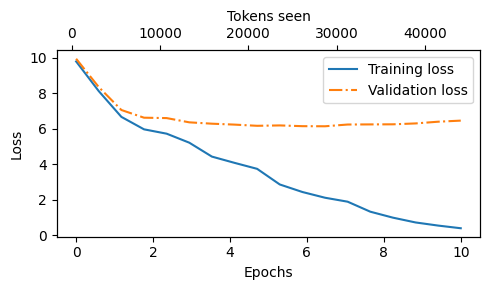

In [225]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  # only show integer labels on x-axis

    # Create a second x-axis for tokens seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(tokens_seen, train_losses, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.savefig("loss-plot.pdf")
    plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

Decoding Strategies To Control Randomness

In [226]:
model.to("cpu")
model.eval()

tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text(
    model = model,
    idx = text_to_token("Every efforts moves you", tokenizer),
    max_new_token = 24,
    context_size=GPT_Config_124M["context_length"]
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every efforts moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed


Temperature Scaling

In [227]:
vocab = { 
    "closer": 0,
    "every": 1, 
    "effort": 2, 
    "forward": 3,
    "inches": 4,
    "moves": 5, 
    "pizza": 6,
    "toward": 7,
    "you": 8,
}
inverse_vocab = {i:k for k,i in vocab.items()}
inverse_vocab

{0: 'closer',
 1: 'every',
 2: 'effort',
 3: 'forward',
 4: 'inches',
 5: 'moves',
 6: 'pizza',
 7: 'toward',
 8: 'you'}

In [228]:
next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)
probas = torch.softmax(next_token_logits, dim=0)
probas

tensor([0.0609, 0.0016, 0.0001, 0.5721, 0.0034, 0.0001, 0.0001, 0.3576, 0.0040])

In [229]:
next_token_id  = torch.argmax(probas).item()
next_token_id

3

In [230]:
inverse_vocab[next_token_id]

'forward'

In [231]:
#torch.manual_seed(123)
next_token_id = torch.multinomial(probas, num_samples=1).item()
print(inverse_vocab[next_token_id])

forward


In [233]:
def print_sample_tokens(probas):
    torch.manual_seed(123)
    sample = [torch.multinomial(probas, num_samples=1).item() for i in range(1_000)]
    sample_ids = torch.bincount(torch.tensor(sample))
    for i, freq in enumerate(sample_ids):
        print(f"{freq}*{inverse_vocab[i]}")
    
print_sample_tokens(probas)

73*closer
0*every
0*effort
582*forward
2*inches
0*moves
0*pizza
343*toward


In [235]:
def softmax_with_temperature(logits, temperature):
    scaled_logits = logits/temperature
    return torch.softmax(scaled_logits, dim=0)

In [237]:
probas.sum()

tensor(1.0000)

In [238]:
temperature = [1, 0.5, 5]

scaled_probas = [softmax_with_temperature(next_token_logits, T) for T in temperature]


In [240]:
len(scaled_probas)

3

In [247]:
scaled_probas[0].sum()

tensor(1.0000)

In [243]:
scaled_probas[1]

tensor([0.0081, 0.0000, 0.0000, 0.7132, 0.0000, 0.0000, 0.0000, 0.2786, 0.0000])

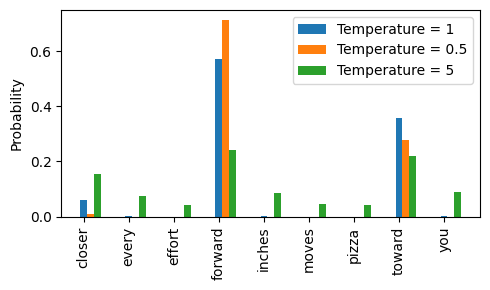

In [245]:
# Plotting
x = torch.arange(len(vocab))
bar_width = 0.15

fig, ax = plt.subplots(figsize=(5, 3))
for i, T in enumerate(temperature):
    rects = ax.bar(x + i * bar_width, scaled_probas[i], bar_width, label=f'Temperature = {T}')

ax.set_ylabel('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()

plt.tight_layout()
plt.savefig("temperature-plot.pdf")
plt.show()

Top-K Sampling

In [248]:
next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

In [249]:
top_k = 3
top_logits, top_pos = torch.topk(next_token_logits,top_k)
print(top_logits,top_pos)

tensor([6.7500, 6.2800, 4.5100]) tensor([3, 7, 0])


In [257]:
new_logits = torch.where(
    condition = next_token_logits < top_logits[-1],
    input=torch.tensor(float("-inf")),
    other=next_token_logits
)
new_logits

tensor([4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf])

In [254]:
next_token_logits < top_logits[-1]

tensor([False,  True,  True, False,  True,  True,  True, False,  True])

In [259]:
torch.softmax(new_logits, dim=0)

tensor([0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000])

Modifying the text generation funtion

In [265]:
def generate(model, idx, max_new_token, context_size, temperature=0.0, top_k=None, eos_id=None):
    for _ in range(max_new_token):
        idx_cond = idx[:, -context_size:]

        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]
        if top_k is not None:
            top_logits, top_pos = torch.topk(logits,top_k)
            new_logits = torch.where(
                condition = logits < top_logits[:,-1],
                input=torch.tensor(float("-inf")),
                other=logits
            )
        if temperature > 0.0:
            logtis = logits/temperature
            probas = torch.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probas, num_samples=1)

        else:
         idx_next = torch.argmax(logits, dim=-1, keepdim=True)
        if idx_next == eos_id:
            break
        idx = torch.cat((idx, idx_next), dim=1)
    return idx

In [266]:
torch.manual_seed(123)
token_ids = generate(
    model=model,
    idx=text_to_token("Every efforts move you", tokenizer),
    max_new_token=15,
    context_size=GPT_Config_124M["context_length"],
    top_k=25,
    temperature=1.4
)

print("Output text /n", token_ids_to_text(token_ids, tokenizer))

Output text /n Every efforts move you not to work on surprise, abanks to face the portraitition of placed


Loading And Saving Model Weights In Pytoch

In [270]:
torch.save(model.state_dict(), "model.path")

Loading Pretrained Model From OpenAI

In [273]:
print("tensorflow version", version("tensorflow"))
print("tqmd version", version("tqdm"))

tensorflow version 2.21.0
tqmd version 4.70.1


In [274]:
from gpt_download import download_and_load_gpt2

In [276]:
settings, params = download_and_load_gpt2(model_size="124M", models_dir="gpt2")

checkpoint: 100%|██████████| 77.0/77.0 [00:00<00:00, 28.5kiB/s]
encoder.json: 100%|██████████| 1.04M/1.04M [00:01<00:00, 600kiB/s] 
hparams.json: 100%|██████████| 90.0/90.0 [00:00<00:00, 19.1kiB/s]
model.ckpt.data-00000-of-00001: 100%|██████████| 498M/498M [12:16<00:00, 676kiB/s]    
model.ckpt.index: 100%|██████████| 5.21k/5.21k [00:00<00:00, 1.60MiB/s]
model.ckpt.meta: 100%|██████████| 471k/471k [00:01<00:00, 413kiB/s]  
vocab.bpe: 100%|██████████| 456k/456k [00:01<00:00, 371kiB/s]  


In [277]:
print("settings", settings)

settings {'n_vocab': 50257, 'n_ctx': 1024, 'n_embd': 768, 'n_head': 12, 'n_layer': 12}


In [279]:
print(params["wte"])
print("token embedding weight tensor dimension", params["wte"].shape)

[[-0.11010301 -0.03926672  0.03310751 ... -0.1363697   0.01506208
   0.04531523]
 [ 0.04034033 -0.04861503  0.04624869 ...  0.08605453  0.00253983
   0.04318958]
 [-0.12746179  0.04793796  0.18410145 ...  0.08991534 -0.12972379
  -0.08785918]
 ...
 [-0.04453601 -0.05483596  0.01225674 ...  0.10435229  0.09783269
  -0.06952604]
 [ 0.1860082   0.01665728  0.04611587 ... -0.09625227  0.07847701
  -0.02245961]
 [ 0.05135201 -0.02768905  0.0499369  ...  0.00704835  0.15519823
   0.12067825]]
token embedding weight tensor dimension (50257, 768)


In [288]:
GPT_CONFIG_124M = {
  "vocab_size":50257,
  "context_length":256,
  "emb_dim":768,
  "n_heads":12,
  "n_layers":12,
  "drop_rate":0.1,
  "qkv_biase":True
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}
# Copy the base configuration and update with specific model settings
model_name = "gpt2-small (124M)"  # Example model name
NEW_CONFIG = GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])
NEW_CONFIG.update({"context_length": 1024, "qkv_bias": True})

gpt = GPTModel(NEW_CONFIG)
gpt.eval();

In [289]:
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(torch.tensor(right))

In [290]:
import numpy as np

def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params['wpe'])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params['wte'])
    
    for b in range(len(params["blocks"])):
        q_w, k_w, v_w = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight, 
            params["blocks"][b]["attn"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias, 
            params["blocks"][b]["attn"]["c_proj"]["b"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight, 
            params["blocks"][b]["mlp"]["c_fc"]["w"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias, 
            params["blocks"][b]["mlp"]["c_fc"]["b"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight, 
            params["blocks"][b]["mlp"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias, 
            params["blocks"][b]["mlp"]["c_proj"]["b"])

        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale, 
            params["blocks"][b]["ln_1"]["g"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift, 
            params["blocks"][b]["ln_1"]["b"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale, 
            params["blocks"][b]["ln_2"]["g"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift, 
            params["blocks"][b]["ln_2"]["b"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])
    
    
load_weights_into_gpt(gpt, params)
gpt.to(device);

In [299]:
torch.manual_seed(123)

token_ids = generate(
    model=gpt,
    idx=text_to_token("efforts moves you", tokenizer).to(device),
    max_new_token=25,
    context_size=NEW_CONFIG["context_length"],
    top_k=50,
    temperature=1.5
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 efforts moves you toward rendering an object. Animations don't have to reveal your weapons by itself; they could even be hidden by the invisible
